In [14]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [15]:
#dataset
keras.utils.set_random_seed(42)
layers = tf.keras.layers
df = pd.read_csv("ecg.csv",header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [16]:
#train n split
X = df.iloc[:,:-1].values.astype("float32")
y = (df.iloc[:,-1].values == 0).astype(int)
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
scaler = MinMaxScaler().fit(Xtr[ytr == 0])
Xtrn = scaler.transform(Xtr[ytr == 0])
Xtes = scaler.transform(Xte)
print(Xtrn.shape, Xtes.shape, yte.sum(), len(yte))

(2335, 140) (1000, 140) 416 1000


In [17]:
Xtrn = Xtrn[..., None]
Xtes = Xtes[..., None]

In [18]:
#layers
inp = keras.Input(shape=(140,1))
x = layers.Conv1D(32,5,strides=2,padding="same",activation="relu")(inp)
x = layers.Conv1D(16,5,strides=2,padding="same",activation="relu")(x)
x = layers.Flatten()(x)
z = layers.Dense(16,activation="relu")(x)
x = layers.Dense(35 * 16,activation="relu")(z)
x = layers.Reshape((35,16))(x)
x = layers.Conv1DTranspose(16,5,strides=2,padding="same",activation="relu")(x)
x = layers.Conv1DTranspose(32,5,strides=2,padding="same",activation="relu")(x)
out = layers.Conv1D(1,5,padding="same",activation="sigmoid")(x)
ae = keras.Model(inp,out)
ae.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 140, 1)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_6 (Conv1D)                    │ (None, 70, 32)              │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_7 (Conv1D)                    │ (None, 35, 16)              │           2,576 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 560)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │           8,976 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 560)                 │           9,520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_2 (Reshape)                  │ (None, 35, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_transpose_4 (Conv1DTranspose) │ (None, 70, 16)              │           1,296 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_transpose_5 (Conv1DTranspose) │ (None, 140, 32)             │           2,592 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_8 (Conv1D)                    │ (None, 140, 1)              │             161 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,313 (98.88 KB)

 Trainable params: 25,313 (98.88 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
#compile
ae.compile(optimizer="adam",loss="mse",metrics=["mae"])
hist = ae.fit(Xtrn,Xtrn,epochs=40,validation_split=0.1,batch_size=64)

Epoch 1/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0223 - mae: 0.1206 - val_loss: 0.0143 - val_mae: 0.0887
Epoch 2/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0121 - mae: 0.0789 - val_loss: 0.0073 - val_mae: 0.0583
Epoch 3/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0067 - mae: 0.0569 - val_loss: 0.0047 - val_mae: 0.0454
Epoch 4/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0044 - mae: 0.0449 - val_loss: 0.0038 - val_mae: 0.0411
Epoch 5/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0038 - mae: 0.0414 - val_loss: 0.0035 - val_mae: 0.0390
Epoch 6/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0034 - mae: 0.0393 - val_loss: 0.0032 - val_mae: 0.0376
Epoch 7/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0031 - mae: 0.0374 - val_loss: 0.0028 - val_mae: 0.0350
Epoch 8/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0028 - mae: 0.0354 - val_loss: 0.0025 - val_mae: 0.0330
Epoch 9/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0025 - mae: 

In [20]:
#reconstruction error
err_train = np.mean((Xtrn - ae.predict(Xtrn))**2,axis=(1,2))
err_test = np.mean((Xtes - ae.predict(Xtes))**2,axis=(1,2))
threshold = np.percentile(err_train,95)
pred = (err_test > threshold).astype(int)
print(threshold, pred.sum(),len(pred))

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
0.0026188750984147153 438 1000


In [21]:
#evaluate
print(classification_report(yte,pred,target_names=["normal","anomaly"],digits=3))
print(confusion_matrix(yte,pred))
print(round(roc_auc_score(yte,err_test),4))

              precision    recall  f1-score   support

      normal      0.995     0.957     0.976       584
     anomaly      0.943     0.993     0.967       416

    accuracy                          0.972      1000
   macro avg      0.969     0.975     0.971      1000
weighted avg      0.973     0.972     0.972      1000

[[559  25]
 [  3 413]]
0.9818


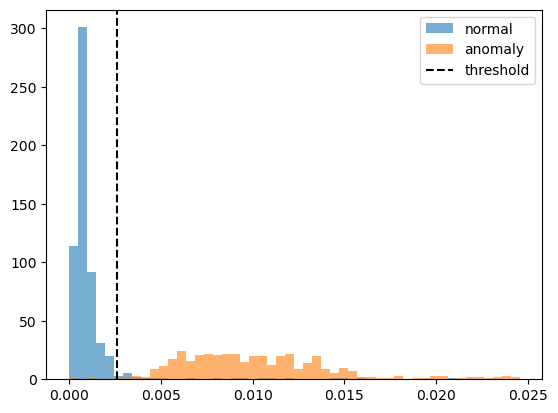

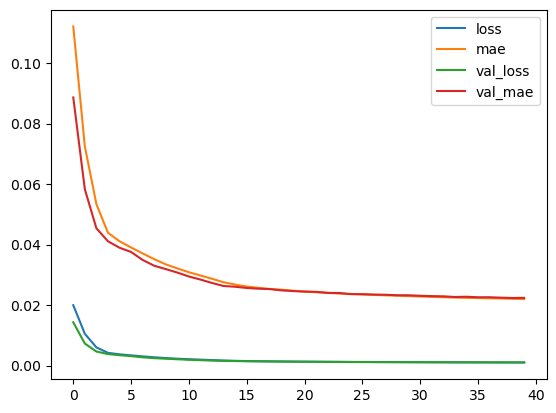

In [22]:
#plot
for k in (0,1):
    plt.hist(err_test[yte==k],50,range=(0,np.percentile(err_test,99)),alpha=0.6,label=["normal","anomaly"][k])
plt.axvline(threshold,color="k",ls="--",label="threshold")
plt.legend()
pd.DataFrame(hist.history).plot();
plt.show()

normal: error 0.001 -> ok
fraud : error 0.007 -> ANOMALY | threshold 0.003
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


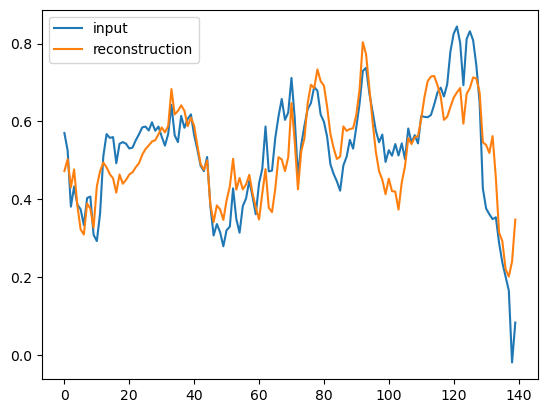

In [23]:
#one example
i = np.where(yte == 0)[0][0]                       # first normal transaction
j = np.where((yte == 1) & (pred == 1))[0][0]       # first fraud the model caught
print(f"normal: error {err_test[i]:.3f} -> {'ANOMALY' if pred[i] else 'ok'}")
print(f"fraud : error {err_test[j]:.3f} -> {'ANOMALY' if pred[j] else 'ok'} | threshold {threshold:.3f}")
plt.plot(Xtes[j], label="input"); plt.plot(ae.predict(Xtes[j:j+1])[0], label="reconstruction")
plt.legend(); plt.show()                           # the gap between the two lines is the error